# Autocomplete and Autocorrect Data Analytics
**Objective:** Build and compare simple autocomplete (next-word and word-completion) and autocorrect (spelling correction) systems on a real text corpus, and measure how well they work.

**Tech stack:** Python, pandas, NLTK, pyspellchecker, collections, matplotlib, seaborn

**Corpus:** Ten books from Project Gutenberg, loaded through NLTK's built-in `gutenberg` corpus (Jane Austen, Lewis Carroll, Herman Melville, G. K. Chesterton and others). This is real public-domain text, so no extra download is needed. You can add more Gutenberg books from gutenberg.org if you want a bigger corpus.

## 0. Setup

In [1]:
import re
import time
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
import nltk
from nltk import FreqDist, ConditionalFreqDist, ngrams
from nltk.corpus import gutenberg, stopwords
from spellchecker import SpellChecker

nltk.download("gutenberg", quiet=True)
nltk.download("stopwords", quiet=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## 1. Collect the text corpus
_Checklist: collect or download a large text corpus_

In [2]:
books = [
    "austen-emma.txt", "austen-persuasion.txt", "austen-sense.txt",
    "carroll-alice.txt", "melville-moby_dick.txt",
    "chesterton-thursday.txt", "chesterton-brown.txt",
    "bryant-stories.txt", "burgess-busterbrown.txt", "edgeworth-parents.txt",
]

raw_counts = {b: len(gutenberg.words(b)) for b in books}
print(pd.Series(raw_counts, name="raw tokens"))
print("Total raw tokens:", sum(raw_counts.values()))

austen-emma.txt            192427
austen-persuasion.txt       98171
austen-sense.txt           141576
carroll-alice.txt           34110
melville-moby_dick.txt     260819
chesterton-thursday.txt     69213
chesterton-brown.txt        86063
bryant-stories.txt          55563
burgess-busterbrown.txt     18963
edgeworth-parents.txt      210663
Name: raw tokens, dtype: int64
Total raw tokens: 1167568


## 2. NLP preprocessing
_Checklist: tokenisation, lowercasing, punctuation removal, stopword removal_

In [3]:
def clean_tokens(words):
    """Lowercase, keep only alphabetic tokens (this removes punctuation and numbers)."""
    out = []
    for w in words:
        w = w.lower()
        if re.fullmatch(r"[a-z]+", w) and (len(w) > 1 or w in ("a", "i")):
            out.append(w)
    return out

# Split EACH book 90% / 10% so train and test cover the same authors and styles
train_tokens, test_tokens = [], []
for b in books:
    toks = clean_tokens(gutenberg.words(b))
    cut = int(len(toks) * 0.9)
    train_tokens += toks[:cut]
    test_tokens += toks[cut:]

print("Train tokens:", len(train_tokens))
print("Test tokens: ", len(test_tokens))
print("Sample:", train_tokens[1000:1015])

Train tokens: 871315
Test tokens:  96818
Sample: ['entirely', 'a', 'match', 'of', 'affection', 'when', 'he', 'was', 'now', 'obliged', 'to', 'part', 'with', 'miss', 'taylor']


In [4]:
stop_words = set(stopwords.words("english"))

# Version WITHOUT stopwords: used only for the word frequency chart
train_no_stop = [w for w in train_tokens if w not in stop_words]
print("Tokens after stopword removal:", len(train_no_stop))

Tokens after stopword removal: 412972


**Why two versions?** _Stopwords like "the" and "of" are removed for the frequency chart because they would dominate it. But for autocomplete they must stay: "of the" is a very common phrase and a keyboard should predict it. Explain in your own words why removing stopwords would damage a next-word model._

## 3. Word frequency analysis
_Checklist: bar chart of the top 20 most frequent words_

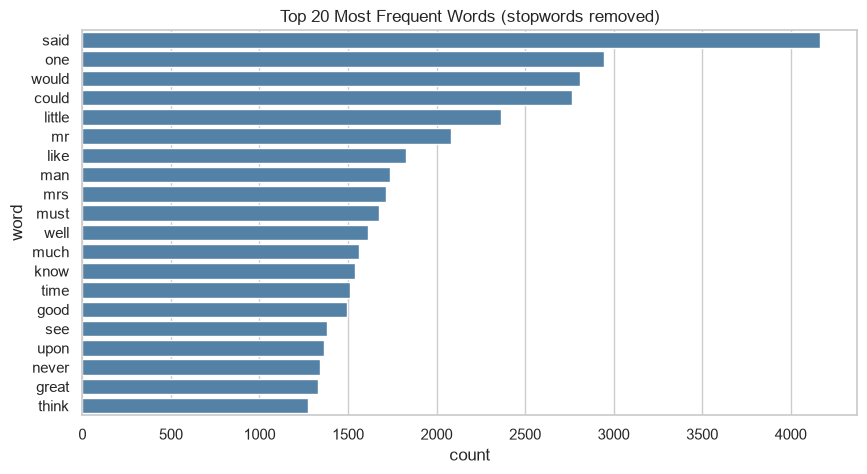

In [5]:
freq = FreqDist(train_no_stop)
top20 = pd.DataFrame(freq.most_common(20), columns=["word", "count"])

sns.barplot(data=top20, x="count", y="word", color="steelblue")
plt.title("Top 20 Most Frequent Words (stopwords removed)")
plt.show()

**Observation:** _Write 2-3 sentences about what this output shows._

## 4. Autocomplete: n-gram models
_Checklist: frequency-based bigram/trigram model that predicts the next word_

In [6]:
# Bigram model: P(next word | previous word)
bi_cfd = ConditionalFreqDist(ngrams(train_tokens, 2))

# Trigram model: P(next word | previous two words)
tri_cfd = ConditionalFreqDist(((a, b), c) for a, b, c in ngrams(train_tokens, 3))

# Overall word frequencies (used as a last-resort fallback)
uni_freq = Counter(train_tokens)
uni_top = [w for w, _ in uni_freq.most_common(10)]

# Precompute the top-3 predictions for every context (much faster than calling most_common each time)
bi_top = {ctx: [w for w, _ in fd.most_common(3)] for ctx, fd in bi_cfd.items()}
tri_top = {ctx: [w for w, _ in fd.most_common(3)] for ctx, fd in tri_cfd.items()}

print("Distinct bigram contexts: ", len(bi_top))
print("Distinct trigram contexts:", len(tri_top))

Distinct bigram contexts:  24954
Distinct trigram contexts: 302692


In [7]:
def fill_from(preds, extra, k):
    for w in extra:
        if w not in preds:
            preds.append(w)
        if len(preds) == k:
            break
    return preds

def predict_bigram(prev_word, k=3):
    """Next word from the last word only; falls back to the most common words."""
    preds = list(bi_top.get(prev_word, []))
    return fill_from(preds, uni_top, k)[:k]

def predict_trigram(w1, w2, k=3):
    """Next word from the last two words; backs off to bigram, then to common words."""
    preds = list(tri_top.get((w1, w2), []))
    if len(preds) < k:
        preds = fill_from(preds, bi_top.get(w2, []), k)
    if len(preds) < k:
        preds = fill_from(preds, uni_top, k)
    return preds[:k]

def autocomplete(text, k=3, model="trigram"):
    words = clean_tokens(text.split())
    if model == "trigram" and len(words) >= 2:
        return predict_trigram(words[-2], words[-1], k)
    return predict_bigram(words[-1], k)

**How the model works:** _In your own words: it counts which word follows each context in the training books, and returns the 3 most frequent followers. What does "backoff" mean here, and why is it needed?_

## 5. Test autocomplete on 10+ prefixes
_Checklist: at least 10 input prefixes, top 3 predictions each_

In [8]:
prefixes = [
    "I do not", "she was very", "it was a", "in the middle of",
    "what do you", "there was a", "I have been", "he said that",
    "you must", "the king", "once upon a", "my dear", "I am sure",
]

rows = []
for p in prefixes:
    rows.append({
        "Prefix": p,
        "Bigram top 3": ", ".join(autocomplete(p, model="bigram")),
        "Trigram top 3": ", ".join(autocomplete(p, model="trigram")),
    })
pd.DataFrame(rows)

,Prefix,Bigram top 3,Trigram top 3
0,I do not,"be, to, a","know, think, you"
1,she was very,"much, well, good","much, fond, well"
2,it was a,"little, very, great","little, very, great"
3,in the middle of,"the, his, a","the, a, this"
4,what do you,"are, know, will","know, think, mean"
5,there was a,"little, very, great","little, very, great"
6,I have been,"a, the, in","a, so, the"
7,he said that,"he, the, she","the, he, she"
8,you must,"be, have, not","be, have, not"
9,the king,"of, and, post","of, and, the"


**Observation:** _Which predictions make sense? Which look odd? Compare the bigram and trigram columns. Why can the trigram model be more accurate, and what is its weakness?_

## 6. Word completion from typed letters
_Extra: suggest full words from the first letters typed, like a phone keyboard_

In [9]:
vocab_sorted = [w for w, _ in uni_freq.most_common()]

# Index: prefix -> 3 most frequent words starting with it
prefix_top = defaultdict(list)
for w in vocab_sorted:
    for L in range(1, min(len(w), 6) + 1):
        lst = prefix_top[w[:L]]
        if len(lst) < 3:
            lst.append(w)

def complete_word(prefix):
    return prefix_top.get(prefix.lower(), [])

for p in ["th", "beau", "wond", "ques", "gen", "mis"]:
    print(f"{p:6s} -> {complete_word(p)}")

th     -> ['the', 'that', 'this']
beau   -> ['beautiful', 'beauty', 'beau']
wond   -> ['wonder', 'wonderful', 'wondrous']
ques   -> ['question', 'questions', 'quest']
gen    -> ['general', 'gentleman', 'gentlemen']
mis    -> ['miss', 'mistress', 'mistaken']


## 7. Autocomplete performance: precision and recall
_Checklist: define and calculate precision and recall for autocomplete_

**Definitions used here** (explain them in your own words):
- A **query** is a position in the held-out test text where we hide the next word and ask the model for 3 suggestions.
- A **hit** means the real next word is among the 3 suggestions.
- **Recall@3** = hits / queries (how often the right word is offered).
- **Precision@3** = hits / total suggestions shown (how many of the suggestions were useful).

With 3 suggestions and only one right answer per query, precision can never exceed 1/3, so it is naturally low. Recall is the more meaningful number here.

In [10]:
def evaluate_autocomplete(predict_fn, tokens, n_queries=20000, k=3):
    hits, suggestions = 0, 0
    queries = min(n_queries, len(tokens) - 2)
    for i in range(2, 2 + queries):
        preds = predict_fn(tokens[i - 2], tokens[i - 1], k)
        suggestions += len(preds)
        hits += tokens[i] in preds
    return {"Queries": queries,
            "Precision@3": hits / suggestions,
            "Recall@3": hits / queries}

models = {
    "Bigram (+ common words)": lambda a, b, k: predict_bigram(b, k),
    "Trigram (+ backoff)": predict_trigram,
}
ac_results = pd.DataFrame({name: evaluate_autocomplete(fn, test_tokens) for name, fn in models.items()}).T
ac_results.round(3)

,Queries,Precision@3,Recall@3
Bigram (+ common words),20000.0,0.080,0.241
Trigram (+ backoff),20000.0,0.084,0.251


In [11]:
# Word completion: type the first 2 or 3 letters, is the real word in the top 3 suggestions?
def evaluate_completion(tokens, prefix_len, n=10000):
    eligible = [w for w in tokens if len(w) > prefix_len + 1][:n]
    hits = sum(w in complete_word(w[:prefix_len]) for w in eligible)
    return hits / len(eligible)

comp = pd.DataFrame({
    "Prefix letters typed": [2, 3, 4],
    "Recall@3": [evaluate_completion(test_tokens, L) for L in [2, 3, 4]],
}).round(3)
comp

,Prefix letters typed,Recall@3
0,2,0.456
1,3,0.664
2,4,0.809


**Observation:** _How much better is the trigram model than the bigram model? How does the chance of the right word being suggested change as more letters are typed?_

## 8. Autocorrect: two approaches
_Checklist: edit-distance based correction; compare at least 2 approaches_

**What is edit distance?** The number of single-character changes (insert, delete, replace) needed to turn one word into another. Below is a custom implementation of the Levenshtein distance, followed by two correctors:

- **Approach A:** `pyspellchecker` (edit distance with a built-in English word list)
- **Approach B:** a custom corrector that uses edit distance 1 or 2 and picks the candidate that is most frequent **in our own corpus**

In [12]:
def levenshtein(a, b):
    """Classic dynamic programming Levenshtein distance."""
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        curr = [i]
        for j, cb in enumerate(b, 1):
            cost = 0 if ca == cb else 1
            curr.append(min(prev[j] + 1,        # delete
                            curr[j - 1] + 1,    # insert
                            prev[j - 1] + cost))  # replace
        prev = curr
    return prev[-1]

for a, b in [("kitten", "sitting"), ("freind", "friend"), ("recieve", "receive"), ("hello", "hello")]:
    print(f"{a:8s} -> {b:8s} distance = {levenshtein(a, b)}")

kitten   -> sitting  distance = 3
freind   -> friend   distance = 2
recieve  -> receive  distance = 2
hello    -> hello    distance = 0


In [13]:
# Approach A: pyspellchecker
spell = SpellChecker(language="en")

def correct_a(word):
    return spell.correction(word) or word

# Approach B: custom corpus-based corrector
vocab_counts = {w: c for w, c in uni_freq.items() if c >= 2}   # ignore very rare tokens (likely typos/names)
letters = string.ascii_lowercase

def edits1(word):
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]
    deletes = [L + R[1:] for L, R in splits if R]
    transposes = [L + R[1] + R[0] + R[2:] for L, R in splits if len(R) > 1]
    replaces = [L + c + R[1:] for L, R in splits if R for c in letters]
    inserts = [L + c + R for L, R in splits for c in letters]
    return set(deletes + transposes + replaces + inserts)

def edits2(word):
    return {e2 for e1 in edits1(word) for e2 in edits1(e1)}

def known(words):
    return {w for w in words if w in vocab_counts}

def correct_b(word):
    if word in vocab_counts:
        return word
    candidates = known(edits1(word)) or known(edits2(word))
    if not candidates:
        return word
    return max(candidates, key=vocab_counts.get)   # most frequent candidate in the corpus

print(correct_a("helo"), correct_b("helo"))

help help


**How approach B decides:** _Explain in your own words: why does it first try distance 1 and only then distance 2, and why does it pick the most frequent candidate among those at the same distance?_

## 9. Test autocorrect on 20+ misspelled words
_Checklist: at least 20 deliberately misspelled words; measure correction accuracy_

In [14]:
misspelled = [
    ("beautifull", "beautiful"), ("freind", "friend"), ("recieve", "receive"),
    ("beleive", "believe"), ("becuase", "because"), ("thorugh", "through"),
    ("togehter", "together"), ("diffrent", "different"), ("anohter", "another"),
    ("betwen", "between"), ("pleasuer", "pleasure"), ("happines", "happiness"),
    ("wich", "which"), ("wolud", "would"), ("coud", "could"),
    ("shoud", "should"), ("thier", "their"), ("wether", "whether"),
    ("tommorow", "tomorrow"), ("necesary", "necessary"), ("occured", "occurred"),
    ("seperate", "separate"), ("agian", "again"), ("allways", "always"),
    ("amoung", "among"), ("wonderfull", "wonderful"), ("yesterady", "yesterday"),
    ("acquaintence", "acquaintance"), ("suprise", "surprise"), ("realy", "really"),
]

# Correctly spelled words that should be left unchanged
correct_words = [
    "the", "friend", "because", "between", "through", "pleasure", "quickly",
    "surprise", "opinion", "important", "always", "again", "would", "could",
    "their", "another", "together", "wonderful", "happiness", "different",
]

# Sanity check: every target word must exist in our corpus vocabulary
missing = [t for _, t in misspelled if t not in vocab_counts]
print("Target words missing from the corpus vocabulary:", missing)

Target words missing from the corpus vocabulary: []


In [15]:
rows = []
for wrong, right in misspelled:
    rows.append({"Typed": wrong, "Target": right,
                 "A: pyspellchecker": correct_a(wrong), "B: custom corpus": correct_b(wrong)})
results = pd.DataFrame(rows)
results["A ok"] = results["A: pyspellchecker"] == results["Target"]
results["B ok"] = results["B: custom corpus"] == results["Target"]
results

,Typed,Target,A: pyspellchecker,B: custom corpus,A ok,B ok
0,beautifull,beautiful,beautiful,beautiful,True,True
1,freind,friend,friend,friend,True,True
2,recieve,receive,receive,receive,True,True
3,beleive,believe,believe,believe,True,True
4,becuase,because,because,because,True,True
5,thorugh,through,through,though,True,False
6,togehter,together,together,together,True,True
7,diffrent,different,different,different,True,True
8,anohter,another,another,another,True,True
9,betwen,between,between,between,True,True


In [16]:
print("Correction accuracy on misspelled words:")
print(f"  A (pyspellchecker):  {results['A ok'].mean():.1%}")
print(f"  B (custom corpus):   {results['B ok'].mean():.1%}")

Correction accuracy on misspelled words:
  A (pyspellchecker):  93.3%
  B (custom corpus):   93.3%


**Observation:** _Which words did each approach get wrong, and why? Look at the wrong suggestions: are they valid words that are just not the intended one?_

## 10. Autocorrect performance: precision, recall and confusion matrix
_Checklist: define and calculate precision and recall; confusion matrix for correct/incorrect before and after_

**Definitions used here** (explain them in your own words):
- The test set has the 30 misspelled words **and** 20 correctly spelled words.
- A **change** is when the corrector outputs something different from the input.
- **Precision** = correct fixes / all changes made (how often a change was a right one).
- **Recall** = correct fixes / misspelled words (how many of the errors were fixed).
- **Confusion matrix:** rows are whether the word was correct or misspelled **before** correction; columns are whether the output is correct or incorrect **after** correction.

In [17]:
test_set = [(w, t) for w, t in misspelled] + [(w, w) for w in correct_words]   # (typed, truth)

def evaluate_corrector(fn):
    outputs, times = [], []
    for typed, truth in test_set:
        t0 = time.perf_counter()
        outputs.append(fn(typed))
        times.append(time.perf_counter() - t0)

    typed = np.array([x[0] for x in test_set])
    truth = np.array([x[1] for x in test_set])
    out = np.array(outputs)

    changed = out != typed
    correct_fix = (out == truth) & (typed != truth)
    n_misspelled = (typed != truth).sum()

    precision = correct_fix.sum() / changed.sum() if changed.sum() else 0
    recall = correct_fix.sum() / n_misspelled
    accuracy = (out == truth).mean()

    before_ok = typed == truth
    after_ok = out == truth
    cm = pd.DataFrame(
        [[(~before_ok & after_ok).sum(), (~before_ok & ~after_ok).sum()],
         [(before_ok & after_ok).sum(), (before_ok & ~after_ok).sum()]],
        index=["Before: misspelled", "Before: correct"],
        columns=["After: correct", "After: incorrect"],
    )
    return {"Precision": precision, "Recall": recall, "Accuracy": accuracy,
            "Avg ms per word": 1000 * np.mean(times)}, cm

res_a, cm_a = evaluate_corrector(correct_a)
res_b, cm_b = evaluate_corrector(correct_b)

comparison = pd.DataFrame({"A: pyspellchecker": res_a, "B: custom corpus": res_b}).T
comparison.round(3)

,Precision,Recall,Accuracy,Avg ms per word
A: pyspellchecker,0.966,0.933,0.96,7.600
B: custom corpus,0.933,0.933,0.96,1.263


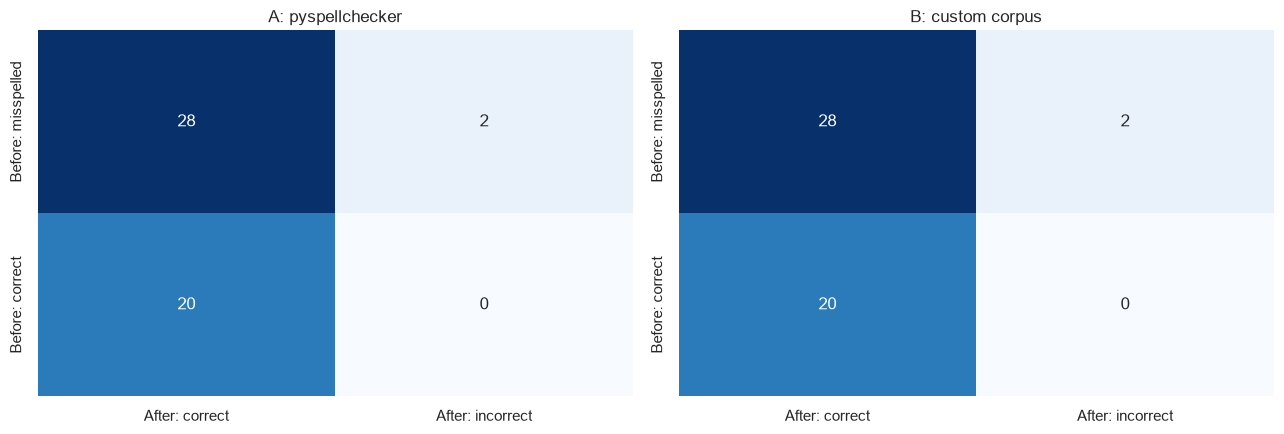

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, cm, title in zip(axes, [cm_a, cm_b], ["A: pyspellchecker", "B: custom corpus"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Observation:** _Read the confusion matrices. How many misspelled words were fixed correctly? Did either corrector damage a word that was already correct? What does that mean for users?_

## 11. Algorithm comparison summary

In [19]:
summary = pd.DataFrame({
    "Task": ["Autocomplete", "Autocomplete", "Autocorrect", "Autocorrect"],
    "Approach": ["Bigram", "Trigram + backoff", "pyspellchecker", "Custom corpus-based"],
    "Main metric": [ac_results.loc["Bigram (+ common words)", "Recall@3"],
                    ac_results.loc["Trigram (+ backoff)", "Recall@3"],
                    res_a["Recall"], res_b["Recall"]],
}).round(3)
summary

,Task,Approach,Main metric
0,Autocomplete,Bigram,0.241
1,Autocomplete,Trigram + backoff,0.251
2,Autocorrect,pyspellchecker,0.933
3,Autocorrect,Custom corpus-based,0.933


**Observation:** _Which approach wins for each task? Why does using the corpus's own word frequencies help (or hurt) the custom corrector on this text?_

## 12. Limitations vs production systems like Google Keyboard
_Write your discussion in your own words. Ideas to cover:_
- _Context: our corrector looks at one word at a time ("their" vs "there"); production systems read the whole sentence_
- _Neural language models (RNN/Transformer) vs simple n-gram counts_
- _Training data: 10 old books vs billions of modern messages (slang, names, emojis)_
- _Personalisation: learning your own vocabulary and typing habits_
- _Speed and memory on a phone, and privacy (on-device learning)_
- _Our model ignores sentence boundaries and punctuation_
- _Typing-error models: real typos depend on keyboard layout (nearby keys), not just edit distance_

## 13. Conclusion
_Summarise: how well did autocomplete and autocorrect perform, which approach was best, what surprised you, and what would you improve first?_